# FitLoop - Data analysis

The cleaning notebook gave us data we can trust. This notebook uses it to answer the board's question:
**is FitLoop's growth healthy, and where should the next euro go?**

We follow the five guiding questions of the brief:

1. Funnel - where does value leak between signup and a paying, staying customer?
2. Segments - which channels / platforms / countries behave differently, and does it survive a like-for-like comparison?
3. Unit economics - CAC, retention, LTV and payback, by channel.
4. What changed in the 18 months, and what did it cause?
5. North Star Metric.

Each section ends with a short *Finding* box that can go straight into the report.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

EXTRACTION = pd.Timestamp("2026-06-30")
PRICE_MONTHLY, PRICE_ANNUAL = 9.99, 59.99

# one fixed colour per channel, used in every chart
CHANNELS = ["Google Ads", "Influencers", "Meta Ads", "Organic", "Referral", "TikTok Ads"]
PAID_CHANNELS = ["Google Ads", "Influencers", "Meta Ads", "TikTok Ads"]
COLOR = dict(zip(CHANNELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
pct = mtick.PercentFormatter(1.0)

The cleaning notebook already removed the 45 test accounts. It also left the missing Meta Ads spend of August 2025 empty, and marked the 827 Meta users of that month with `in_cac = False`.

**Rule:** these 827 users are counted when we check who pays and who stays, but not in the CAC (Customer Acquisition Cost), because we don't know what they cost.

This cell only checks the data; it does not change it.



In [2]:
user = pd.read_csv("../data/users_cleaned.csv")
mark = pd.read_csv("../data/marketing_spend_cleaned.csv")
user = user.drop(columns=["Unnamed: 0"], errors="ignore")
mark = mark.drop(columns=["Unnamed: 0"], errors="ignore")

date_cols = ["signup_date", "trial_start_date", "subscription_start_date", "subscription_end_date"]
for c in date_cols:
    user[c] = pd.to_datetime(user[c])
mark["month"] = pd.to_datetime(mark["month"])

# safety checks on the cleaned files
assert not user["user_id"].str.startswith("QA_").any(), "test accounts still present - re-run cleaning.ipynb"
assert "in_cac" in user.columns, "column in_cac missing - re-run cleaning.ipynb"
user["in_cac"] = user["in_cac"].astype(bool)

print("users:", len(user), "| spend rows:", len(mark))
print("users excluded from CAC:", (~user["in_cac"]).sum())
print("spend rows with missing spend:")
display(mark[mark["spend_eur"].isna()])

users: 70237 | spend rows: 72
users excluded from CAC: 827
spend rows with missing spend:


,month,channel,spend_eur
30,2025-08-01,Meta Ads,NaN


**Observation.** The data loads correctly: 70,237 users, 72 spend rows (18 months x 4 paid channels), no test accounts, and only one missing value (Meta Ads, August 2025).


#### Helper columns
Extra columns added to make the analysis easier. They do not change the data.

- `cohort`: the month the user signed up. Used to compare users who joined at different times.
- `trial`, `paid`, `churned`: did the user start a trial, pay, or cancel? (True when the matching date is filled in.)
- `mature`: did the user sign up at least 14 days before 30 June 2026?
  - **Why 14 days:** in our data, a trial starts at most 6 days after signup, and every user pays exactly 7 days after the trial starts. So it can take up to 13 days from signup to the first payment.
  - **Why it matters:** a user who signed up a few days before 30 June has not had time to pay yet. Counting them as "did not pay" would make the last weeks look worse than they are.
- `paid_days`: how many days the user has paid for, until they cancelled, or until 30 June 2026 if they are still subscribed (right-censored: we do not know yet when they will stop).
- `payments`: how many times the user has been billed so far: one payment per started month (monthly plan) or per started year (annual plan).
- `revenue`: payments × price (€9.99 per month or €59.99 per year). This is the money collected until 30 June 2026.



In [3]:
user["cohort"] = user["signup_date"].dt.to_period("M")
user["trial"] = user["trial_start_date"].notna()
user["paid"] = user["subscription_start_date"].notna()
user["churned"] = user["subscription_end_date"].notna()
user["mature"] = user["signup_date"] <= EXTRACTION - pd.Timedelta(days=14)

end = user["subscription_end_date"].fillna(EXTRACTION)
user["paid_days"] = (end - user["subscription_start_date"]).dt.days

period = np.where(user["plan"] == "annual", 365, 30.44)
price = np.where(user["plan"] == "annual", PRICE_ANNUAL, PRICE_MONTHLY)
user["payments"] = np.where(user["paid"], np.maximum(1, np.ceil(user["paid_days"] / period)), 0)
user["revenue"] = user["payments"] * price

mature = user[user["mature"]]
print("mature users:", len(mature), "of", len(user))

user.head()

mature users: 67944 of 70237


,user_id,signup_date,channel,country,platform,activated_d7,trial_start_date,subscription_start_date,plan,subscription_end_date,in_cac,cohort,trial,paid,churned,mature,paid_days,payments,revenue
0,U101247,2025-01-20,Organic,FR,iOS,0,NaT,NaT,NaN,NaT,True,2025-01,False,False,False,True,NaN,0.000,0.000
1,U119636,2025-08-19,TikTok Ads,FR,Android,1,2025-08-20,NaT,NaN,NaT,True,2025-08,True,False,False,True,NaN,0.000,0.000
2,U105849,2025-03-16,Organic,BE,Android,1,NaT,NaT,NaN,NaT,True,2025-03,False,False,False,True,NaN,0.000,0.000
3,U147354,2026-02-11,TikTok Ads,FR,Android,1,2026-02-13,NaT,NaN,NaT,True,2026-02,True,False,False,True,NaN,0.000,0.000
4,U118277,2025-08-06,Organic,FR,iOS,1,NaT,NaT,NaN,NaT,True,2025-08,False,False,False,True,NaN,0.000,0.000


**Observation.**
- 67,944 of 70,237 users (97%) had enough time to pay. The other 2,293 signed up in the last two weeks before 30 June 2026, so it is too early to know if they will pay. We leave them out when we measure how many users pay.
- The first rows show a typical user: they sign up but never pay. About 9 in 10 users are like this. Their payment columns are empty (NaT = empty date, NaN = empty value) because they never subscribed. This is normal, not an error, so we keep them.
- Two of these users (rows 1 and 3, both from TikTok Ads) started a free trial but did not pay after it.



## 1. The signup dashboard view: "growth looks great"

First we reproduce what the CEO sees: signups per month, by channel.

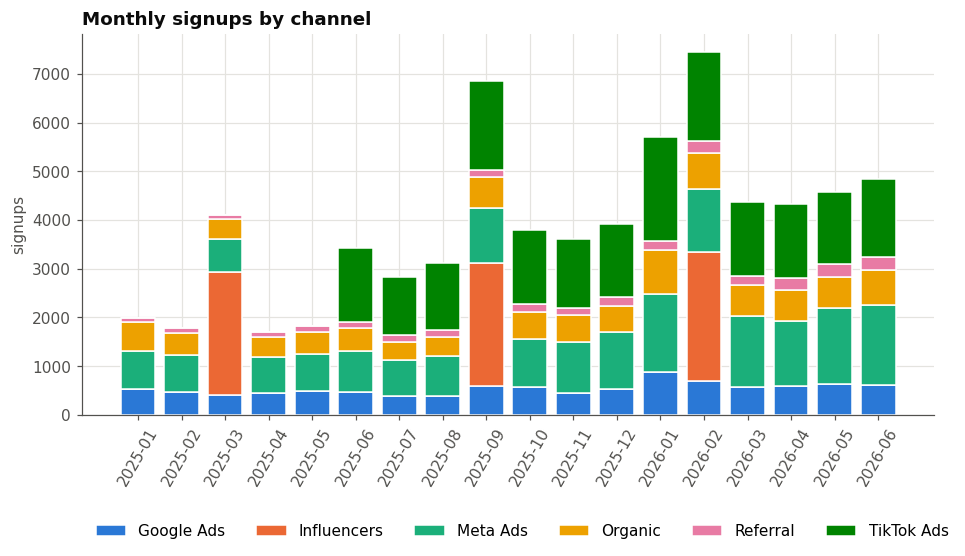

avg signups/month: first 3 months 2,625  ->  last 3 months 4,583  (x1.7)

share of all signups by channel:
channel
TikTok Ads    0.291
Meta Ads      0.276
Organic       0.144
Google Ads    0.138
Influencers   0.110
Referral      0.042
Name: proportion, dtype: float64


In [4]:
monthly = user.pivot_table(index="cohort", columns="channel", values="user_id", aggfunc="count").fillna(0)[CHANNELS]

fig, ax = plt.subplots()
bottom = np.zeros(len(monthly))
x = monthly.index.astype(str)
for ch in CHANNELS:
    ax.bar(x, monthly[ch], bottom=bottom, color=COLOR[ch], label=ch, edgecolor="white", linewidth=1)
    bottom += monthly[ch].values
ax.set_title("Monthly signups by channel")
ax.set_ylabel("signups")
ax.tick_params(axis="x", rotation=60)
ax.legend(ncol=6, loc="upper left", bbox_to_anchor=(0, -0.25))
plt.show()

first3, last3 = monthly.iloc[:3].sum(axis=1).mean(), monthly.iloc[-3:].sum(axis=1).mean()
print(f"avg signups/month: first 3 months {first3:,.0f}  ->  last 3 months {last3:,.0f}  (x{last3/first3:.1f})")
print("\nshare of all signups by channel:")
print((user["channel"].value_counts(normalize=True)).round(3))

**Observation.**
- FitLoop gets a lot more signups now than at the start. It went from about 2,600 a month in early 2025 to about 4,600 a month in mid 2026.
- The three tall bars are Influencers campaigns. They bring a big jump for one month and then stop.
- TikTok Ads started in June 2025 and brings around 1,500 new users every month since then.
- Most users come from TikTok and Meta ads (more than half). Very few come from referrals.




**Finding 1.** The dashboard is right that signups are growing. FitLoop gets about 1.7 times more new users a month now than at the start.
But most of this growth is paid for. About 8 in 10 users come from paid channels (TikTok, Meta, Google and Influencers). Only about 2 in 10 come for free (Organic and Referral).
So more signups alone does not mean healthy growth. The next sections check if these paid users stay, pay, and are worth what they cost.


## 2. The funnel: where does value leak?

Steps: **signup -> activated in 7 days (3 workouts) -> trial -> paid -> still paying at extraction.**
Activation is not a mandatory step (a user can start a trial without activating), so we also look at how much activation changes the next steps.

,users,% of signups
Signed up,67944,1.000
Activated (3 workouts/7d),24027,0.354
Started trial,18702,0.275
Paid,6979,0.103
Still paying at 30 Jun,4366,0.064


trial -> paid: 37.3%


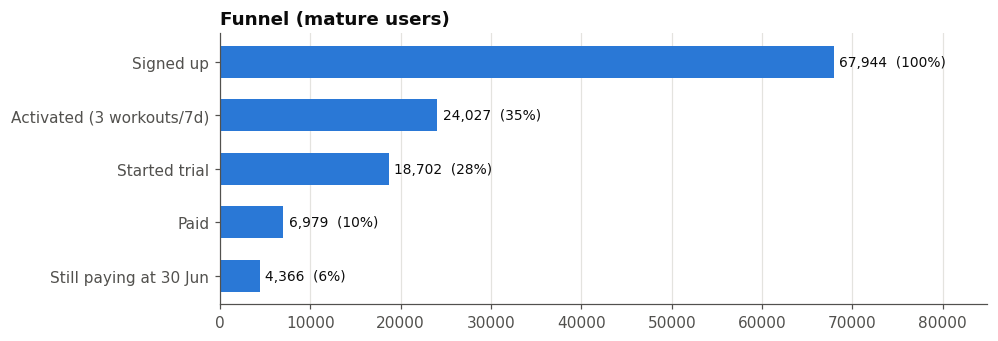

In [5]:
m = mature
funnel = pd.Series({
    "Signed up":               len(m),
    "Activated (3 workouts/7d)": m["activated_d7"].sum(),
    "Started trial":           m["trial"].sum(),
    "Paid":                    m["paid"].sum(),
    "Still paying at 30 Jun":  (m["paid"] & ~m["churned"]).sum(),
})
funnel_tbl = pd.DataFrame({"users": funnel, "% of signups": funnel / funnel.iloc[0]})
display(funnel_tbl)
print(f"trial -> paid: {m.loc[m.trial, 'paid'].mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(funnel.index[::-1], funnel.values[::-1], color="#2a78d6", height=0.6)
for i, v in enumerate(funnel.values[::-1]):
    ax.text(v + 600, i, f"{v:,.0f}  ({v / funnel.iloc[0]:.0%})", va="center", color=INK, fontsize=9)
ax.set_title("Funnel (mature users)")
ax.set_xlim(0, funnel.iloc[0] * 1.25)
ax.grid(axis="y", visible=False)
plt.show()

**Observation.**
- Out of every 100 people who sign up, only about 35 do 3 workouts in their first week, 28 start a free trial, 10 pay, and 6 are still paying on 30 June 2026.
- The biggest drop is right at the start. About 65 out of 100 users don't really use the app in their first week.
- About 1 in 3 people who start a trial go on to pay (37%).
- Of the people who paid, about 1 in 3 have already stopped paying.


#### Does activation matter?
We compare users who activated in their first week with those who didn't.

In [6]:
act = mature.groupby("activated_d7").agg(
    users=("user_id", "size"),
    trial_rate=("trial", "mean"),
    paid_rate=("paid", "mean"),
)
act["trial_to_paid"] = mature[mature.trial].groupby("activated_d7")["paid"].mean()
act.index = act.index.map({0: "not activated", 1: "activated"})
display(act)
print(f"an activated user is {act.loc['activated','paid_rate'] / act.loc['not activated','paid_rate']:.0f}x more likely to pay")

,users,trial_rate,paid_rate,trial_to_paid
activated_d7,,,,
not activated,43917,0.100,0.016,0.159
activated,24027,0.596,0.262,0.439


an activated user is 17x more likely to pay


**Observation.** 

An activated user is 17x more likely to pay. Doing 3 workouts in the first week is the best early signal of a future customer. So yes activation matters.

**Finding 2.** Most new users give up in their first week. Only about 1 in 3 does 3 workouts in the first 7 days.
The ones who do are the ones who pay. They are about 16 times more likely to become paying customers, and almost all paying users (9 out of 10) did this first.
So instead of only bringing in more new users, FitLoop should help new users get to their 3rd workout.


## 3. Channels and segments: who behaves differently?

Same funnel, split by channel (mature users).

,signups,activation,trial_rate,paid_rate,annual_share,trial_to_paid
channel,,,,,,
Referral,2793,0.598,0.401,0.216,0.234,0.538
Organic,9761,0.497,0.351,0.156,0.247,0.443
Google Ads,9414,0.442,0.315,0.140,0.255,0.445
Meta Ads,18587,0.380,0.289,0.113,0.248,0.391
Influencers,7705,0.273,0.233,0.071,0.229,0.303
TikTok Ads,19684,0.213,0.204,0.045,0.238,0.222


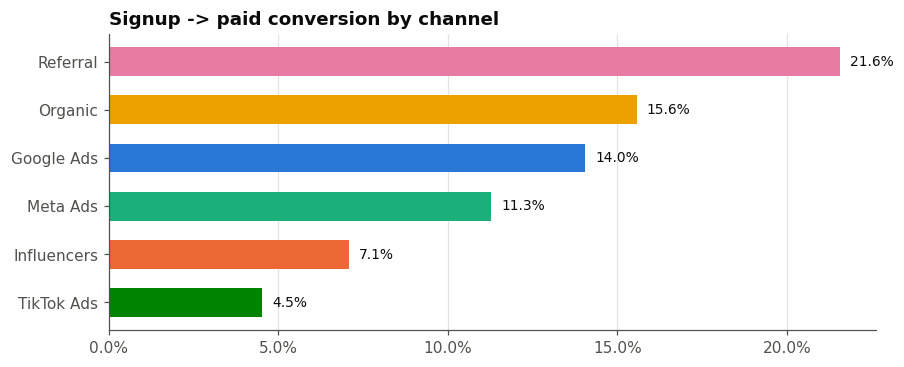

In [7]:
by_ch = mature.groupby("channel").agg(
    signups=("user_id", "size"),
    activation=("activated_d7", "mean"),
    trial_rate=("trial", "mean"),
    paid_rate=("paid", "mean"),
    annual_share=("plan", lambda s: (s == "annual").sum() / s.notna().sum()),
).loc[CHANNELS]
by_ch["trial_to_paid"] = mature[mature.trial].groupby("channel")["paid"].mean()
display(by_ch.sort_values("paid_rate", ascending=False))

fig, ax = plt.subplots(figsize=(9, 3.5))
s = by_ch["paid_rate"].sort_values()
ax.barh(s.index, s.values, color=[COLOR[c] for c in s.index], height=0.6)
for i, v in enumerate(s.values):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center", color=INK, fontsize=9)
ax.xaxis.set_major_formatter(pct)
ax.set_title("Signup -> paid conversion by channel")
ax.grid(axis="y", visible=False)
plt.show()

**Observation.** 

A Referral user is ~5x more likely to pay than a TikTok user. The annual plan share is similar everywhere (23-26% of payers), so channels differ in how many users pay, not in which plan they choose.

#### Fair comparison (like with like)
A channel can look good or bad for the wrong reason. For example, TikTok brings mostly Android users, so it might look weak only because of that.
To be fair, we compare the channels in smaller groups: first iOS users only, then Android users only, then before and after October 2025 (the funnel numbers change from that month, we show this in section 6).
If the channel order stays the same in every group, the channel itself really is better or worse.


In [8]:
mature = mature.assign(period=np.where(mature["signup_date"] >= "2025-10-01", "after Oct 2025", "before Oct 2025"))

print("paid rate - channel x platform")
display(mature.pivot_table(index="channel", columns="platform", values="paid", aggfunc="mean").loc[CHANNELS])

print("paid rate - channel x period")
display(mature.pivot_table(index="channel", columns="period", values="paid", aggfunc="mean")
        .loc[CHANNELS, ["before Oct 2025", "after Oct 2025"]])

print("platform mix by channel (share iOS)")
display(mature.groupby("channel")["platform"].apply(lambda s: (s == "iOS").mean()).loc[CHANNELS])

paid rate - channel x platform


platform,Android,iOS
channel,,
Google Ads,0.141,0.140
Influencers,0.070,0.071
Meta Ads,0.116,0.111
Organic,0.160,0.153
Referral,0.226,0.210
TikTok Ads,0.047,0.041


paid rate - channel x period


period,before Oct 2025,after Oct 2025
channel,,
Google Ads,0.119,0.158
Influencers,0.063,0.086
Meta Ads,0.088,0.129
Organic,0.129,0.175
Referral,0.164,0.248
TikTok Ads,0.037,0.049


platform mix by channel (share iOS)


channel
Google Ads    0.624
Influencers   0.617
Meta Ads      0.627
Organic       0.623
Referral      0.638
TikTok Ads    0.224
Name: platform, dtype: float64

**Observation.**
- iOS and Android users pay at about the same rate inside each channel. For example, TikTok is 4.7% on Android and 4.1% on iOS. So the phone type is not the problem.
- After October 2025 every channel gets better, but the order doesn't change. Referral is still the best and TikTok is still the worst.
- TikTok brings mostly Android users. Only about 2 in 10 TikTok users have an iPhone, while in the other channels about 6 in 10 do.
- So TikTok's low result is not because of Android or because of timing. TikTok just brings users who pay less.


In [9]:
print("funnel by platform")
display(mature.groupby("platform")[["activated_d7", "trial", "paid"]].mean())
print("funnel by country")
display(mature.groupby("country", observed=True)[["activated_d7", "trial", "paid"]].mean())

funnel by platform


,activated_d7,trial,paid
platform,,,
Android,0.321,0.261,0.091
iOS,0.386,0.289,0.114


funnel by country


,activated_d7,trial,paid
country,,,
BE,0.358,0.278,0.102
CH,0.350,0.270,0.104
FR,0.354,0.275,0.103
LU,0.353,0.287,0.106
Unknown,0.336,0.250,0.094


**Observation.**
- At first iOS looks better than Android: 11.4% of iPhone users pay, against 9.1% of Android users.
- But this is only because TikTok brings mostly Android users, and TikTok users pay less. Inside the same channel, iOS and Android pay about the same (previous table).
- Country makes almost no difference. In BE (Belgium), CH (Switzerland), FR (France) and LU (Luxembourg), about 10 out of 100 users pay.
- "Unknown" means the country was missing in the data. These users pay a bit less (9.4%), but they are only about 2% of users.


**Finding 3.** Where users come from matters a lot. About 22 out of 100 Referral users end up paying, but only about 4 or 5 out of 100 TikTok users do.
We checked this fairly, inside iPhone users only, inside Android users only, and before and after October 2025. The order of the channels stays the same every time, so the difference really comes from the channel.
The phone and the country don't matter. iPhone only looks better because TikTok brings mostly Android users. When we compare inside the same channel, iPhone and Android users pay the same, and all countries pay about the same too.
So if FitLoop wants more paying users, it should look at which channels it spends on, not at phone type or country.


## 4. Retention: do paying users stay?

Here we check how long people keep paying on the monthly plan.

We draw a curve that shows, month after month, how many paying users are still paying.
Many users were still paying on 30 June 2026, so we don't know yet when they will stop. To handle this we use a Kaplan-Meier curve. Each month it only counts the users we could follow for that long.

We also calculate the monthly churn rate, which is how many paying users stop each month. We use it later to estimate LTV (Lifetime Value, how much money one paying user brings in total).


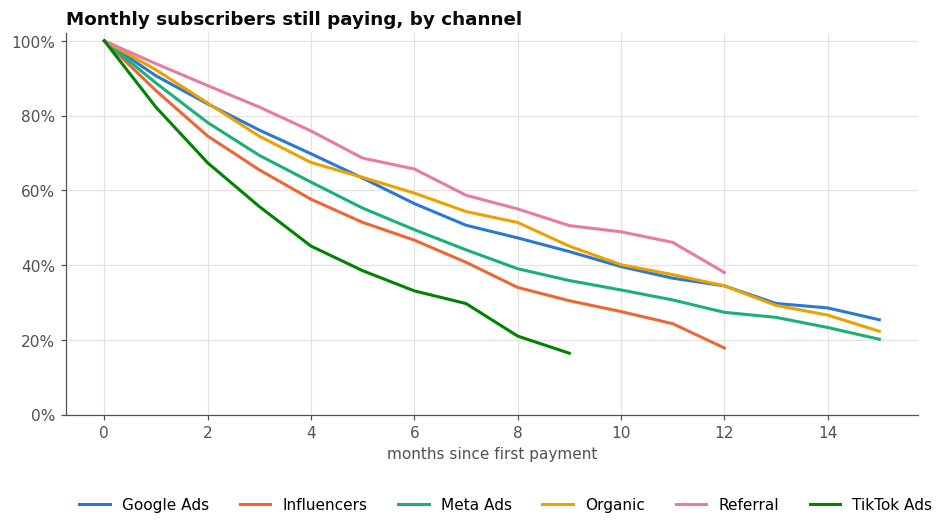

In [10]:
def survival_curve(d, max_m=16):
    months = np.round(d["paid_days"] / 30.44).astype(int)
    churned = d["churned"].values
    s, out = 1.0, [1.0]
    for k in range(1, max_m + 1):
        at_risk = (months >= k).sum()
        events = ((months == k) & churned).sum()
        if at_risk < 30:            # too few users left to be reliable
            break
        s *= 1 - events / at_risk
        out.append(s)
    return pd.Series(out, name="survival")

monthly_subs = user[user["paid"] & (user["plan"] == "monthly")]

fig, ax = plt.subplots()
for ch in CHANNELS:
    sc = survival_curve(monthly_subs[monthly_subs["channel"] == ch])
    ax.plot(sc.index, sc.values, color=COLOR[ch], label=ch)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 1.02)
ax.set_xlabel("months since first payment")
ax.set_title("Monthly subscribers still paying, by channel")
ax.legend(ncol=6, loc="upper left", bbox_to_anchor=(0, -0.18))
plt.show()

**Observation.**
- In every channel, people stop paying little by little each month. The biggest drop is in the first few months.
- Referral users stay the longest. After 6 months, about 2 in 3 are still paying.
- TikTok users leave the fastest. After 6 months only about 1 in 3 are still paying, and after 9 months fewer than 2 in 10.
- Google, Organic and Meta are in the middle, and Influencers is close to TikTok.
- Some lines stop early (for example TikTok at 9 months) because there aren't enough users yet to follow for longer.

In our view, TikTok is weak twice. Fewer of its users pay, and the ones who pay leave sooner. So each TikTok payer brings less money than a payer from the other channels. Referral is the opposite, with more users paying and staying longer. The starting months after payment are when FitLoop loses the most subscribers, so that is the time to work on keeping them.


In [11]:
def churn_rate(d):
    return d["churned"].sum() / (d["paid_days"].sum() / 30.44)

ret = pd.DataFrame({
    "monthly_subscribers": monthly_subs.groupby("channel").size(),
    "monthly_churn": monthly_subs.groupby("channel").apply(churn_rate),
}).loc[CHANNELS]
ret["avg_lifetime_months"] = 1 / ret["monthly_churn"]
display(ret)
print(f"all channels: monthly churn {churn_rate(monthly_subs):.1%}")

annual = user[user["paid"] & (user["plan"] == "annual")]
eligible = annual[annual["subscription_start_date"] <= EXTRACTION - pd.Timedelta(days=365)]
renewal = 1 - eligible["churned"].mean()
print(f"annual plan: {len(eligible)} subscribers reached their renewal date, {renewal:.0%} renewed")

/var/folders/7l/64cn3h61387ftlj4msnf10qr0000gn/T/ipykernel_8737/576015639.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "monthly_churn": monthly_subs.groupby("channel").apply(churn_rate),


,monthly_subscribers,monthly_churn,avg_lifetime_months
channel,,,
Google Ads,993,0.088,11.310
Influencers,420,0.128,7.812
Meta Ads,1594,0.109,9.164
Organic,1153,0.087,11.489
Referral,468,0.070,14.287
TikTok Ads,689,0.175,5.703


all channels: monthly churn 10.4%
annual plan: 298 subscribers reached their renewal date, 54% renewed


**Observation.**
- Monthly plan: every month, about 10 out of 100 monthly subscribers stop paying. On average a monthly subscriber stays about 10 months.
- It depends a lot on the channel. Referral users stay about 14 months and Organic and Google users about 11, but TikTok users stay only about 6 months.
- Yearly plan: 298 yearly subscribers reached the end of their first year, and about half of them (54%) paid for another year. So a yearly subscriber stays on average about 2 years.
- Yearly subscribers stay much longer than monthly ones (about 2 years against about 10 months).


**Finding 4.** Paying users don't all stay the same amount of time. On the monthly plan, Referral users keep paying for about 14 months, but TikTok users only for about 6 months.
This makes TikTok weak twice. Fewer of its users pay, and the ones who do pay leave much faster.
The yearly plan keeps people much longer (about 2 years against about 10 months on monthly), but only 1 in 4 payers chooses it.
In our view, keeping subscribers matters as much as getting new ones. A user who stays 14 months brings more than twice the money of one who stays 6. In the next section we check if each channel's users bring in more money than they cost to get.


## 5. Unit economics: does each user bring more money than they cost?

All amounts are in euros. We only count money paid by users, because the data has no information about FitLoop's costs.

- CAC (Customer Acquisition Cost) is how much FitLoop spends on ads to get users.
  - CAC per signup = ad spend ÷ number of signups.
  - CAC per payer = ad spend ÷ number of paying users. This is the one that matters, because only paying users bring money.
- LTV (Lifetime Value) is how much money one paying user brings in total before they stop paying.
  - Monthly plan: 9.99 ÷ the channel's monthly churn (the share of subscribers who stop each month).
  - Yearly plan: 59.99 ÷ (1 − 54% renewal). We use the same renewal rate for every channel because each channel has too few yearly users.
  - Then we mix the two, based on how many payers in each channel chose monthly or yearly.
- LTV/CAC (Lifetime Value to Customer Acquisition Cost ratio) compares what a payer brings with what they cost to get. Above 1, the channel makes back its ad money.
- Payback is how many months of payments it takes to win back the ad money spent on one payer.

Organic and Referral users are free (no ad spend), so they have no CAC.
In August 2025 the Meta ad spend is missing, so we leave out that month and its 827 Meta users when we calculate CAC.


In [12]:
spend = mark.groupby("channel")["spend_eur"].sum()      # NaN (Meta Aug 2025) is skipped
cac_users = mature[mature["in_cac"]]

ue = by_ch[["annual_share"]].copy()
ue["signups"] = cac_users.groupby("channel").size()
ue["payers"] = cac_users.groupby("channel")["paid"].sum()
ue["spend_eur"] = spend
ue["cac_per_signup"] = ue["spend_eur"] / ue["signups"]
ue["cac_per_payer"] = ue["spend_eur"] / ue["payers"]

ltv_monthly = PRICE_MONTHLY / ret["monthly_churn"]
ltv_annual = PRICE_ANNUAL / (1 - renewal)
ue["ltv_per_payer"] = (1 - ue["annual_share"]) * ltv_monthly + ue["annual_share"] * ltv_annual
ue["ltv_to_cac"] = ue["ltv_per_payer"] / ue["cac_per_payer"]

monthly_rev_per_payer = (1 - ue["annual_share"]) * PRICE_MONTHLY + ue["annual_share"] * PRICE_ANNUAL / 12
ue["payback_months"] = ue["cac_per_payer"] / monthly_rev_per_payer

cols = ["spend_eur", "signups", "payers", "cac_per_signup", "cac_per_payer", "ltv_per_payer", "ltv_to_cac", "payback_months"]
display(ue[cols].round(2))

tot_spend = spend.sum()
paid_payers = ue.loc[PAID_CHANNELS, "payers"].sum()   # in_cac users only
print(f"total spend {tot_spend:,.0f} EUR | blended CAC per payer (paid channels) {tot_spend / paid_payers:,.0f} EUR")

,spend_eur,signups,payers,cac_per_signup,cac_per_payer,ltv_per_payer,ltv_to_cac,payback_months
channel,,,,,,,,
Google Ads,"49,810.000",9414,1322,5.290,37.680,117.690,3.120,4.320
Influencers,"27,000.000",7705,545,3.500,49.540,90.290,1.820,5.600
Meta Ads,"105,700.000",17760,2011,5.950,52.560,101.440,1.930,6.000
Organic,NaN,9761,1520,NaN,NaN,118.900,NaN,NaN
Referral,NaN,2793,602,NaN,NaN,140.090,NaN,NaN
TikTok Ads,"47,250.000",19684,892,2.400,52.970,74.670,1.410,6.020


total spend 229,760 EUR | blended CAC per payer (paid channels) 48 EUR


**Observation.**
- TikTok looks cheap but isn't. Getting one signup costs only 2.40 €, the cheapest of all channels. But so few TikTok users pay that getting one paying user costs about 53 €, the most expensive of all.
- Google Ads gives the best return. For every 1 € spent, Google payers bring back about 3.10 €. Meta brings back about 1.90 €, Influencers 1.80 € and TikTok only 1.40 €.
- Meta gets almost half of the ad budget (105,700 € of 229,760 €), but it returns much less than Google.
- Referral (140 €) and Organic (119 €) payers bring the most money, and these users cost FitLoop nothing in ads.
- Google wins back its ad money fastest, in about 4 months. Meta and TikTok need about 6 months.


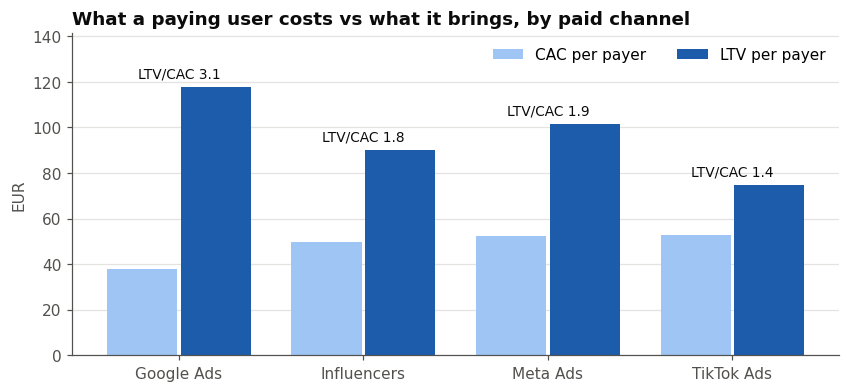

In [13]:
d = ue.loc[PAID_CHANNELS]
fig, ax = plt.subplots(figsize=(9, 3.8))
xx = np.arange(len(d))
ax.bar(xx - 0.2, d["cac_per_payer"], width=0.38, color="#9ec5f4", label="CAC per payer")
ax.bar(xx + 0.2, d["ltv_per_payer"], width=0.38, color="#1c5cab", label="LTV per payer")
for i, (c, l) in enumerate(zip(d["cac_per_payer"], d["ltv_per_payer"])):
    ax.text(i, max(c, l) + 4, f"LTV/CAC {l / c:.1f}", ha="center", color=INK, fontsize=9)
ax.set_xticks(xx, d.index)
ax.set_ylabel("EUR")
ax.set_ylim(0, d["ltv_per_payer"].max() * 1.2)
ax.set_title("What a paying user costs vs what it brings, by paid channel")
ax.legend(loc="upper right", ncol=2)
ax.grid(axis="x", visible=False)
plt.show()

**Observation.** CAC per payer is quite similar across channels (≈38-53 €), but LTV is not (≈75-118 €). LTV is what separates the channels.
Google earns ≈3 € for every 1 € spent, TikTok only ≈1.4 €. The weakness of TikTok is mainly a retention and conversion problem, not a price problem.

#### CAC over time
Is a euro spent today still buying as much as before? CAC per payer by month and paid channel (mature cohorts only).

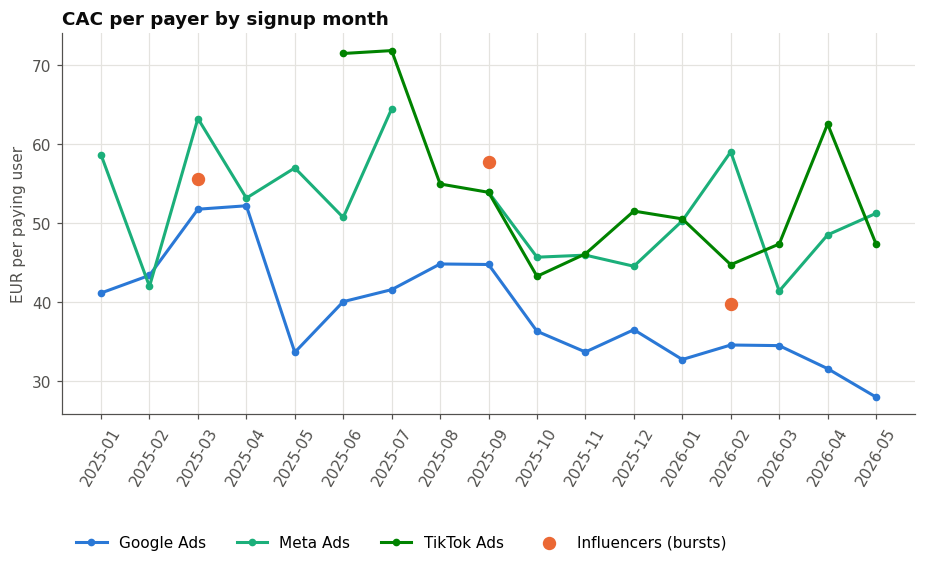

,spend,signups,cac_per_signup
cohort,,,
2025-01,"3,750.000",780.000,4.810
2025-02,"3,270.000",773.000,4.230
2025-03,"2,970.000",677.000,4.390
2025-04,"3,240.000",732.000,4.430
2025-05,"3,530.000",773.000,4.570
2025-06,"3,850.000",838.000,4.590
2025-07,"3,350.000",738.000,4.540
2025-08,NaN,827.000,NaN
2025-09,"5,980.000","1,117.000",5.350


In [14]:
payers_m = mature[mature["channel"].isin(PAID_CHANNELS)].groupby(["cohort", "channel"])["paid"].sum()
spend_m = mark.assign(cohort=mark["month"].dt.to_period("M")).set_index(["cohort", "channel"])["spend_eur"]
cac_m = (spend_m / payers_m).unstack("channel").replace(np.inf, np.nan)
cac_m = cac_m[cac_m.index < "2026-06"]                     # June 2026 not mature yet
cac_m = cac_m.where(spend_m.unstack("channel").reindex(cac_m.index) > 0)   # no spend -> no CAC

fig, ax = plt.subplots()
for ch in ["Google Ads", "Meta Ads", "TikTok Ads"]:
    ax.plot(cac_m.index.astype(str), cac_m[ch], color=COLOR[ch], marker="o", markersize=4, label=ch)
infl = cac_m["Influencers"].dropna()
ax.scatter(infl.index.astype(str), infl.values, color=COLOR["Influencers"], s=60, zorder=3, label="Influencers (bursts)")
ax.set_ylabel("EUR per paying user")
ax.set_title("CAC per payer by signup month")
ax.tick_params(axis="x", rotation=60)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.28))
plt.show()

meta = pd.DataFrame({"spend": spend_m.xs("Meta Ads", level="channel"),
                     "signups": monthly["Meta Ads"]})
meta["cac_per_signup"] = meta["spend"] / meta["signups"]
display(meta.round(2))

**Observation.**
- Google Ads keeps getting cheaper over time. It costs less and less to get a paying user.
- Meta Ads doesn't improve. FitLoop spends much more on Meta than before, but each new user costs more. Spending more on Meta brings less for each euro.
- TikTok was very expensive when it started, and is still one of the most expensive channels.
- Influencers was a bit cheaper in the last campaign (February 2026).
- August 2025 is missing for Meta because the spend data is missing for that month.


**Finding 5.** Every paid channel brings back more money than it costs, but some are much better than others.
Google Ads is clearly the best. It brings back about 3 € for every 1 € spent, and it keeps getting cheaper over time.
TikTok is the weakest. Its signups are cheap, but few of them pay and the ones who pay leave fast, so it brings back only about 1.40 € for every 1 €.
Meta gets almost half of the budget, but spending more on it hasn't made it better. Each new Meta user now costs more than before.
Organic and Referral bring the users who pay the most, and they cost nothing in ads.

In our view, the next euro should go to Google Ads before Meta or TikTok.



## 5b. Unit economics by cohort

Here we check if users who joined at different times are worth different amounts.
A cohort is a group of users who signed up in the same 3 months (a quarter). We use quarters because single months have too few users.

How we did it:
- We only use signups up to 31 May 2026. June 2026 users haven't had enough time to pay yet.
- CAC (Customer Acquisition Cost, the ad money spent to get users) uses paid channels only, like in section 5. Meta's August 2025 users are left out because the spend for that month is missing.
- LTV (Lifetime Value, the money one paying user brings in total) is shown only for users who joined by the end of 2025. Newer users haven't been around long enough, so we can't see yet how fast they stop paying.
- "Revenue to date" is the money users really paid up to 30 June 2026, with no guessing about the future.


In [15]:
cut = pd.Timestamp("2026-06-01")
cu = user[user["signup_date"] < cut].copy()
cu["quarter"] = cu["signup_date"].dt.to_period("Q")
paid_ch = cu["channel"].isin(PAID_CHANNELS) & cu["in_cac"]

spend_q = (mark[mark["month"] < cut]
           .assign(quarter=lambda d: d["month"].dt.to_period("Q"))
           .groupby("quarter")["spend_eur"].sum())

coh = pd.DataFrame({
    "signups": cu.groupby("quarter").size(),
    "activation": cu.groupby("quarter")["activated_d7"].mean(),
    "paid_rate": cu.groupby("quarter")["paid"].mean(),
    "spend_eur": spend_q,
    "payers_paid_channels": cu[paid_ch].groupby("quarter")["paid"].sum(),
})
coh["cac_per_payer"] = coh["spend_eur"] / coh["payers_paid_channels"]

cohort_monthly = cu[cu["paid"] & (cu["plan"] == "monthly")]
coh["monthly_churn"] = cohort_monthly.groupby("quarter").apply(churn_rate)
coh["annual_share"] = cu[cu["paid"]].groupby("quarter")["plan"].apply(lambda s: (s == "annual").mean())

old_enough = coh.index <= pd.Period("2025Q4")          # at least 6 months of history
ltv_q = ((1 - coh["annual_share"]) * PRICE_MONTHLY / coh["monthly_churn"]
         + coh["annual_share"] * PRICE_ANNUAL / (1 - renewal))
coh["ltv_per_payer"] = ltv_q.where(old_enough)
coh["monthly_churn"] = coh["monthly_churn"].where(old_enough)
coh["ltv_to_cac"] = coh["ltv_per_payer"] / coh["cac_per_payer"]

coh["revenue_to_date"] = cu[paid_ch].groupby("quarter")["revenue"].sum()
coh["revenue_per_eur_spent"] = coh["revenue_to_date"] / coh["spend_eur"]

coh.index = coh.index.astype(str).str.replace("2026Q2", "2026Q2 (Apr-May)")
display(coh.drop(columns=["annual_share"]).round(3))

/var/folders/7l/64cn3h61387ftlj4msnf10qr0000gn/T/ipykernel_8737/380556559.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  coh["monthly_churn"] = cohort_monthly.groupby("quarter").apply(churn_rate)


,signups,activation,paid_rate,spend_eur,payers_paid_channels,cac_per_payer,monthly_churn,ltv_per_payer,ltv_to_cac,revenue_to_date,revenue_per_eur_spent
quarter,,,,,,,,,,,
2025Q1,7875,0.315,0.095,"26,580.000",522,50.920,0.099,107.375,2.109,"43,055.960",1.620
2025Q2,6960,0.296,0.093,"20,880.000",415,50.313,0.102,106.623,2.119,"29,807.570",1.428
2025Q3,12792,0.264,0.077,"35,050.000",645,54.341,0.118,94.622,1.741,"37,379.040",1.066
2025Q4,11326,0.394,0.112,"36,370.000",846,42.991,0.103,105.653,2.458,"44,377.190",1.220
2026Q1,17534,0.394,0.110,"60,880.000",1388,43.862,NaN,NaN,NaN,"58,967.790",0.969
2026Q2 (Apr-May),8904,0.417,0.121,"32,370.000",726,44.587,NaN,NaN,NaN,"21,887.600",0.676


**Observation.**

**Observation.**
- Users who joined in July to September 2025 were the worst group. Fewer of them paid, they cost the most to get, and they stopped paying the fastest. This was TikTok's first full quarter and the time of the September Influencers campaign.
- Users who joined from October 2025 onward are better. More of them do 3 workouts in their first week, and a paying user costs less to get (about 43 € instead of 50–54 €).
- Every 2025 group has already paid back more than its ad cost. The January–March 2026 group is almost there.
- The newest groups (2026) haven't been around long enough, so we can't say yet how long they will keep paying. That is why some cells are empty.


#### Retention by cohort
How many monthly subscribers are still paying after 1, 3, 6, 9 and 12 months. Users are grouped by the 3 months (quarter) in which they first paid.
An empty cell means that group hasn't been paying long enough to measure yet.


In [16]:
subs = user[user["paid"] & (user["plan"] == "monthly")].copy()
subs["pay_quarter"] = subs["subscription_start_date"].dt.to_period("Q")
observed_m = (EXTRACTION - subs["subscription_start_date"]).dt.days / 30.44
paid_m = subs["paid_days"] / 30.44

ret_coh = {}
for k in [1, 3, 6, 9, 12]:
    eligible = observed_m >= k                              # started paying at least k months before extraction
    still = ~subs["churned"] | (paid_m >= k + 0.5)          # still paying after k months
    g = subs[eligible].assign(still=still[eligible]).groupby("pay_quarter")
    ret_coh[f"after {k} months"] = g["still"].mean().where(g.size() >= 30)

ret_coh = pd.DataFrame(ret_coh)
ret_coh.insert(0, "monthly_subscribers", subs.groupby("pay_quarter").size())
ret_coh.index = ret_coh.index.astype(str)
display(ret_coh.round(3))

,monthly_subscribers,after 1 months,after 3 months,after 6 months,after 9 months,after 12 months
pay_quarter,,,,,,
2025Q1,512,0.898,0.729,0.541,0.410,0.305
2025Q2,491,0.898,0.713,0.505,0.379,0.273
2025Q3,687,0.879,0.670,0.479,0.314,NaN
2025Q4,987,0.884,0.687,0.492,NaN,NaN
2026Q1,1447,0.885,0.696,NaN,NaN,NaN
2026Q2,1193,0.894,NaN,NaN,NaN,NaN


**Observation.**
- In every group, about 9 in 10 monthly subscribers pay again after the first month.
- After that, people slowly leave. After 6 months about half are still paying, and after 1 year only about 3 in 10.
- The first group (January–March 2025) keeps its subscribers a bit better than the later groups.
- People who started paying in July–September 2025 leave the fastest. This is the same weak group as in the previous table.
- From October 2025, more users pay, but they don't stay longer. After 6 months the October–December 2025 group is at about the same level as the earlier groups.


#### Payback by cohort
Does the ad money come back, and how fast?

Each line is one group of users who signed up in the same 3 months (2025Q1 = January to March 2025). Lighter lines are older groups, darker lines are newer ones.
The line shows how much money the group has paid so far for every 1 € spent on ads to get them.
When a line goes above the dashed line (1.0), that group has paid back its ad cost. Newer groups have shorter lines because they joined later.


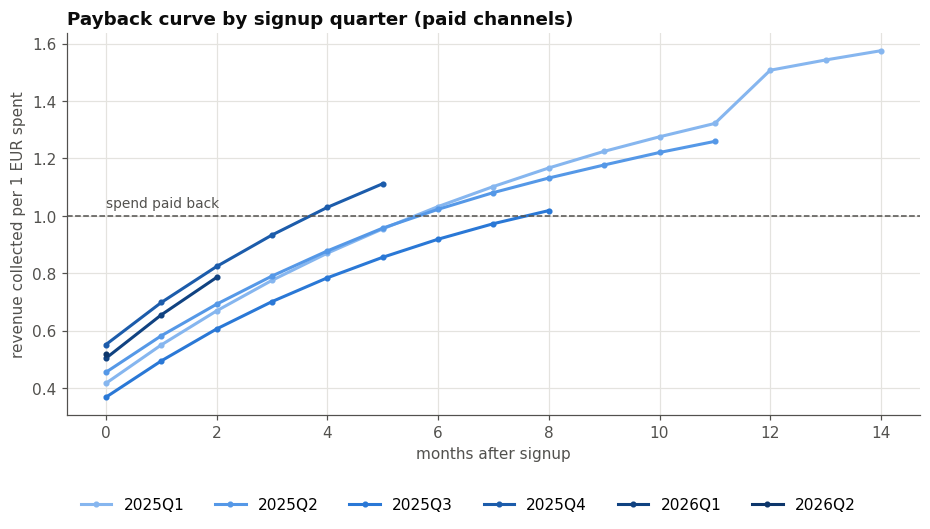

months needed to pay back the spend: {'2025Q1': 6, '2025Q2': 6, '2025Q3': 8, '2025Q4': 4, '2026Q1': None, '2026Q2': None}


In [17]:
pc = cu[paid_ch & cu["paid"]]
events = []
for plan, period_days, plan_price in [("monthly", 30.44, PRICE_MONTHLY), ("annual", 365, PRICE_ANNUAL)]:
    d = pc[pc["plan"] == plan]
    rep = d.loc[d.index.repeat(d["payments"].astype(int))]
    k = rep.groupby(level=0).cumcount()
    pay_date = rep["subscription_start_date"] + pd.to_timedelta(k * period_days, unit="D")
    events.append(pd.DataFrame({
        "quarter": rep["quarter"].values,
        "month": ((pay_date - rep["signup_date"]).dt.days // 30.44).astype(int).values,
        "revenue": plan_price,
    }))
events = pd.concat(events)

curve = events.pivot_table(index="month", columns="quarter", values="revenue", aggfunc="sum").fillna(0).cumsum()
curve = curve / spend_q.reindex(curve.columns).values

ramp = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]   # older cohorts lighter
fig, ax = plt.subplots()
payback = {}
for q, c in zip(curve.columns, ramp):
    max_m = int((EXTRACTION - q.end_time).days // 30.44)    # months fully observed for the whole cohort
    s = curve[q].loc[:max(max_m, 0)]
    ax.plot(s.index, s.values, color=c, label=str(q), marker="o", markersize=3)
    crossed = s[s >= 1]
    payback[str(q)] = crossed.index[0] if len(crossed) else None
ax.axhline(1, color=MUTED, linestyle="--", linewidth=1)
ax.text(0, 1.03, "spend paid back", color=MUTED, fontsize=9)
ax.set_xlabel("months after signup")
ax.set_ylabel("revenue collected per 1 EUR spent")
ax.set_title("Payback curve by signup quarter (paid channels)")
ax.legend(ncol=6, loc="upper left", bbox_to_anchor=(0, -0.18))
plt.show()

print("months needed to pay back the spend:", payback)

**Observation.**
- All 2025 groups have already paid back their ad cost, in 4 to 8 months.
- The newest groups (2026) start faster than all the older ones, so they should pay back sooner.

In our view, FitLoop's ads do pay off, and they now pay off faster than before. But it still takes several months, so FitLoop has to wait a while before the money comes back.


**Finding 5b.** When users joined matters.
Users who joined in July–September 2025 were the worst group. Fewer paid, they cost the most to get, and they left the fastest. It took 8 months to win back their ad cost.
Users who joined from October 2025 are cheaper to turn into payers, because more of them do 3 workouts in their first week. The October–December 2025 group paid back its ad cost in only 4 months.
But they don't stay longer. Only about 3 in 10 monthly subscribers are still paying after one year, in every group.
In our view, FitLoop got better at turning new users into payers, but not at keeping them. Keeping subscribers is the next problem to fix.


## 6. What changed during the 18 months?

We follow three numbers by signup month: activation (3 workouts in the first 7 days), trial to paid, and signup to paid.


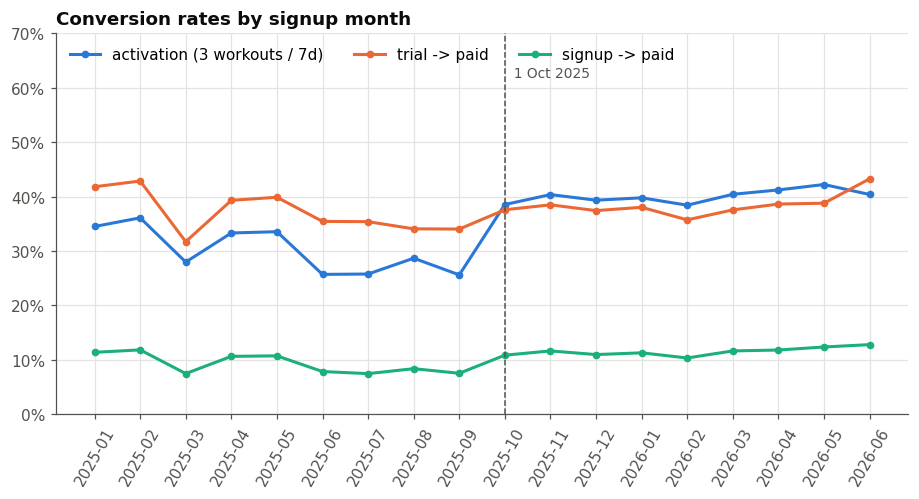

In [18]:
trend = mature.groupby("cohort").agg(activation=("activated_d7", "mean"),
                                    trial_rate=("trial", "mean"),
                                    paid_rate=("paid", "mean"))
trend["trial_to_paid"] = mature[mature.trial].groupby("cohort")["paid"].mean()

fig, ax = plt.subplots()
xs = trend.index.astype(str)
for col, c, lab in [("activation", "#2a78d6", "activation (3 workouts / 7d)"),
                    ("trial_to_paid", "#eb6834", "trial -> paid"),
                    ("paid_rate", "#1baf7a", "signup -> paid")]:
    ax.plot(xs, trend[col], color=c, marker="o", markersize=4, label=lab)
ax.axvline("2025-10", color=MUTED, linestyle="--", linewidth=1)
ax.text("2025-10", 0.62, "  1 Oct 2025", color=MUTED, fontsize=9)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.7)
ax.set_title("Conversion rates by signup month")
ax.tick_params(axis="x", rotation=60)
ax.legend(loc="upper left", ncol=3)
plt.show()

**Observation.**
- Activation (blue) was about 35% at the start. It dropped to about 26% from June to September 2025, when TikTok started bringing many users. On 1 October 2025 it jumped to about 40% and stayed there.
- Signup to paid (green) moves with activation. It was low in mid 2025 (about 8%) and went up to about 11 to 13% after October 2025. When more users activate, more users pay.
- Trial to paid (orange) stays roughly the same for all 18 months (32 to 43%), with no jump in October.
- The dips in March and September 2025 are the Influencers campaign months.

In our view, something on 1 October 2025 helped more new users do their 3 workouts, and that brought more payers. The data doesn't say what it was. The trial step didn't improve, so that is still a place to work on.


In [19]:
print("activation rate by channel, before vs after 1 Oct 2025")
display(mature.pivot_table(index="channel", columns="period", values="activated_d7", aggfunc="mean")
        .loc[CHANNELS, ["before Oct 2025", "after Oct 2025"]])

print("does activation still convert the same way after the change?")
display(mature.pivot_table(index="activated_d7", columns="period", values="paid", aggfunc="mean")
        [["before Oct 2025", "after Oct 2025"]])

daily = user[(user["signup_date"] >= "2025-09-15") & (user["signup_date"] <= "2025-10-15")]
print("daily activation around the change:")
print(daily.groupby(daily["signup_date"].dt.date)["activated_d7"].mean().round(2).to_string())

activation rate by channel, before vs after 1 Oct 2025


period,before Oct 2025,after Oct 2025
channel,,
Google Ads,0.348,0.516
Influencers,0.243,0.331
Meta Ads,0.300,0.431
Organic,0.382,0.583
Referral,0.478,0.671
TikTok Ads,0.161,0.235


does activation still convert the same way after the change?


period,before Oct 2025,after Oct 2025
activated_d7,,
0,0.016,0.016
1,0.262,0.261


daily activation around the change:
signup_date
2025-09-15   0.210
2025-09-16   0.250
2025-09-17   0.250
2025-09-18   0.230
2025-09-19   0.270
2025-09-20   0.240
2025-09-21   0.280
2025-09-22   0.250
2025-09-23   0.310
2025-09-24   0.270
2025-09-25   0.250
2025-09-26   0.270
2025-09-27   0.250
2025-09-28   0.250
2025-09-29   0.250
2025-09-30   0.270
2025-10-01   0.380
2025-10-02   0.440
2025-10-03   0.360
2025-10-04   0.380
2025-10-05   0.450
2025-10-06   0.350
2025-10-07   0.330
2025-10-08   0.450
2025-10-09   0.410
2025-10-10   0.360
2025-10-11   0.410
2025-10-12   0.410
2025-10-13   0.340
2025-10-14   0.350
2025-10-15   0.420


**Observation.**
- After 1 October 2025, more users activate in every channel. For example, Organic went from about 38% to 58% and TikTok from 16% to 24%. Because all channels went up together, the cause is not one ad channel.
- It happened on one exact day. Up to 30 September about 25% of new users activated each day, and from 1 October it was suddenly 35 to 45%.
- Activated users pay at the same rate as before (26%), and so do non-activated users (1.6%). So FitLoop didn't get better users, it just got more of them to do their 3 workouts.

In our view, something changed for all users on 1 October 2025. The data doesn't tell us what it was, so FitLoop should check what happened that day, because it worked.


**Finding 6.** Four things changed in the 18 months:
1. June 2025, TikTok Ads starts. It brings many new users, but few of them do their 3 workouts, so the average activation drops from about 35% to 26%.
2. March 2025, September 2025 and February 2026, Influencers campaigns. Each one brings about 2,500 signups for 9,000 €, but few of these users pay.
3. 1 October 2025, activation jumps from about 26% to about 40% overnight, in every channel. Because activated users pay just as often as before, more users end up paying, about 11 in 100 instead of 8 or 9.
4. From September 2025, FitLoop spends much more on Meta Ads, but each new Meta user costs more than before.

What didn't change is the trial step. About 1 in 3 people who start a trial pay, all 18 months long.
In our view, the 1 October change is the best thing that happened to FitLoop. The data doesn't say what it was, so FitLoop should find out and build on it. The trial step is the next thing to improve.


## 7. Is there a growth loop? Referrals

Referral signups grew every month. If they come from existing paying users, FitLoop has a loop: more subscribers -> more referrals -> more subscribers.
We compare monthly referral signups with the number of active subscribers at the start of the month.

In [20]:
months = pd.period_range("2025-01", "2026-06", freq="M")
active_start = []
for p in months:
    t = p.to_timestamp()
    active = user["paid"] & (user["subscription_start_date"] < t) & (user["subscription_end_date"].isna() | (user["subscription_end_date"] >= t))
    active_start.append(active.sum())

loop = pd.DataFrame({"active_subscribers": active_start,
                     "referral_signups": monthly["Referral"].reindex(months).values}, index=months.astype(str))
loop["referrals_per_100_subs"] = (loop["referral_signups"] / loop["active_subscribers"] * 100).replace(np.inf, np.nan)
display(loop)

valid = loop[loop["active_subscribers"] > 0]
print(f"correlation subscribers vs referral signups: {valid['active_subscribers'].corr(valid['referral_signups']):.2f}")

,active_subscribers,referral_signups,referrals_per_100_subs
2025-01,0,95.000,NaN
2025-02,153,98.000,64.052
2025-03,357,98.000,27.451
2025-04,624,104.000,16.667
2025-05,779,125.000,16.046
2025-06,912,119.000,13.048
2025-07,1074,136.000,12.663
2025-08,1228,140.000,11.401
2025-09,1390,149.000,10.719
2025-10,1700,149.000,8.765


correlation subscribers vs referral signups: 0.96


**Observation.**
- A referral is a new user who joined because an existing user invited them.
- As FitLoop gets more paying users, it also gets more referrals, going from about 95 to about 270 a month.
- But each paying user brings fewer referrals than before. At the start, 100 paying users brought about 17 referrals a month. Now they bring only about 6.
- Some referrals came in even before anyone was paying, so not every referral comes from a paying user.

In our view, referrals are still growing, but each user brings fewer of them over time. Referral users are the best users FitLoop has, so FitLoop should try giving a reward for each referral.



**Finding 7.** FitLoop has a small growth loop: more paying users bring more referrals, and referrals become paying users.
Referral users are the best users FitLoop has. They do their 3 workouts the most, pay the most often, stay the longest, and bring the most money (about 140 € each). They also cost nothing in ads.
But the loop is getting weaker. 100 paying users used to bring about 17 referrals a month, and now they bring about 6.
Both numbers grow over time, so we can't be fully sure that subscribers cause the referrals. The data shows no referral reward today.
In our view, FitLoop should test a referral reward with an A/B test (a test comparing version A against version B), with one group of users getting a reward for inviting and one not. If it works, it is the cheapest way to grow.


## 8. North Star Metric

A NSM (North Star Metric) is the one number the whole company watches to know if it is growing in a healthy way.
A good NSM should:
1. Go up when paying users go up.
2. Be known early, not months later.
3. Not go up just because FitLoop buys lots of cheap, low-quality users.

We test four options, month by month (signups up to May 2026): signups, activated users (users who do 3 workouts in their first 7 days), trials, and paying users.


correlation with the number of paying users (1 = moves exactly together):
signups           0.908
activated_users   0.997
trials            0.991


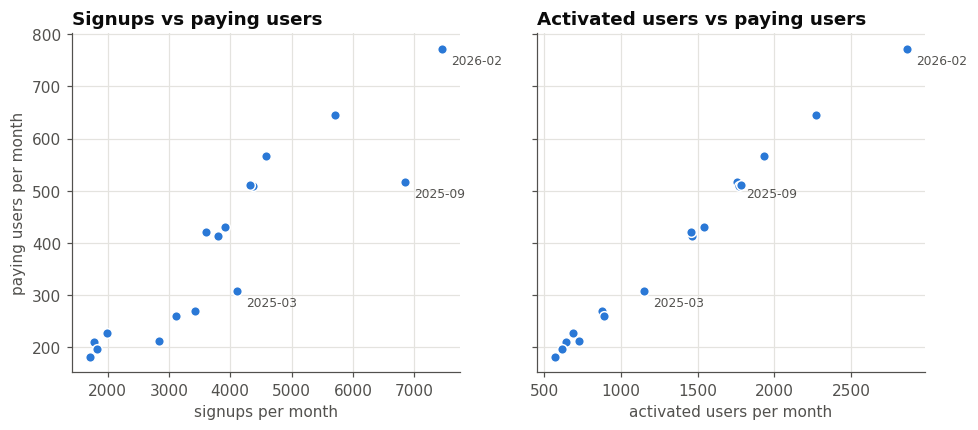

,signups,activated_users,trials,payers
cohort,,,,
2025-03,4111,1150,971,308
2025-09,6850,1755,1519,517
2025-10,3799,1464,1099,413
2026-02,7452,2863,2161,772
2026-03,4377,1769,1358,510


In [21]:
nsm = (user[user["signup_date"] < cut]
       .groupby("cohort")
       .agg(signups=("user_id", "size"), activated_users=("activated_d7", "sum"),
            trials=("trial", "sum"), payers=("paid", "sum")))

print("correlation with the number of paying users (1 = moves exactly together):")
print(nsm.corr()["payers"].drop("payers").round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col, title in [(axes[0], "signups", "Signups vs paying users"),
                       (axes[1], "activated_users", "Activated users vs paying users")]:
    ax.scatter(nsm[col], nsm["payers"], color="#2a78d6", s=40, edgecolor="white", linewidth=1)
    for m in ["2025-03", "2025-09", "2026-02"]:
        p = pd.Period(m)
        ax.annotate(m, (nsm.loc[p, col], nsm.loc[p, "payers"]), textcoords="offset points", xytext=(6, -10),
                    fontsize=8, color=MUTED)
    ax.set_xlabel(col.replace("_", " ") + " per month")
    ax.set_title(title)
axes[0].set_ylabel("paying users per month")
plt.show()

display(nsm.loc[["2025-03", "2025-09", "2025-10", "2026-02", "2026-03"]])

**Observation.**
- The number of activated users goes up and down almost exactly like the number of paying users. Signups don't follow paying users as closely.
- Signups can fool you. September 2025 had almost twice as many signups as October 2025 (6,850 against 3,799), but only a few more paying users (517 against 413).
- In the left chart, some months sit far below the others, for example March and September 2025 (Influencers campaigns), which had many signups but few payers. In the right chart all months sit on one straight line.

In our view, activated users is a much better number to watch than signups, because it tells FitLoop early how many people will pay.


In [22]:
share = pd.DataFrame({
    "share_of_signups": mature["channel"].value_counts(normalize=True),
    "share_of_activated_users": mature.loc[mature["activated_d7"] == 1, "channel"].value_counts(normalize=True),
    "share_of_payers": mature.loc[mature["paid"], "channel"].value_counts(normalize=True),
}).loc[CHANNELS]
display(share.round(3))

,share_of_signups,share_of_activated_users,share_of_payers
channel,,,
Google Ads,0.139,0.173,0.189
Influencers,0.113,0.088,0.078
Meta Ads,0.274,0.294,0.301
Organic,0.144,0.202,0.218
Referral,0.041,0.070,0.086
TikTok Ads,0.290,0.174,0.128


**Observation.**
- TikTok Ads brings almost 3 in 10 signups, but only about 1 in 10 paying users. Influencers also gets smaller along the way.
- Google, Organic and Referral get bigger along the way. Their share of payers is higher than their share of signups.
- Meta stays about the same at every step (about 3 in 10).
- The share of activated users from each channel is much closer to the share of payers than the share of signups is.

In our view, buying cheap TikTok signups makes signups look big, but barely moves activated users. That's why activated users is a better number to watch than signups.


**Finding 8.** Our NSM (North Star Metric) is the number of new users each month who do 3 workouts in their first 7 days.

Why this number:
- It follows paying users almost exactly. When it goes up, paying users go up too. Signups don't follow paying users as well.
- It is known early, just 7 days after signup. Paying users and money come weeks or months later.
- It can't be faked by buying cheap users. TikTok brings almost 3 in 10 signups but fewer than 2 in 10 activated users.
- Everyone can help move it. Marketing can pick better channels, and the 1 October 2025 change raised it in every channel.

Why not the others? Signups can be bought, so they look good without meaning much. Paying users are known too late. Trials are almost as good, but they come one step after activation.

It doesn't show how long people keep paying (only about 3 in 10 monthly subscribers still pay after one year). So FitLoop should watch it together with how many subscribers stop each month.
This is based on 17 months of data.


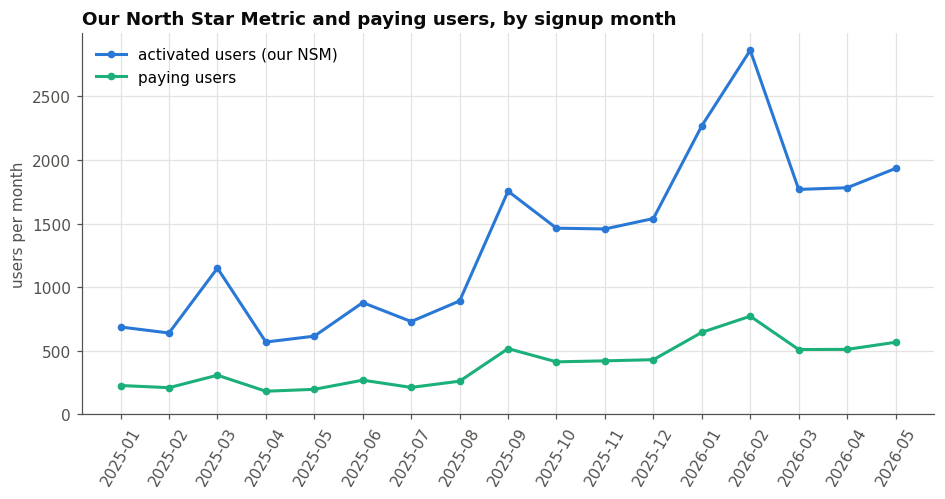

In [23]:
fig, ax = plt.subplots()
xs = nsm.index.astype(str)
ax.plot(xs, nsm["activated_users"], color="#2a78d6", marker="o", markersize=4, label="activated users (our NSM)")
ax.plot(xs, nsm["payers"], color="#1baf7a", marker="o", markersize=4, label="paying users")
ax.set_ylim(0)
ax.set_ylabel("users per month")
ax.set_title("Our North Star Metric and paying users, by signup month")
ax.tick_params(axis="x", rotation=60)
ax.legend(loc="upper left")
plt.show()


**Observation.**
- The two lines go up and down together. When more new users do their 3 workouts, more users pay.
- Activated users grew from about 600 a month in early 2025 to about 1,900 to 2,900 a month in 2026.


## 9. Summary: answers to the five questions

### 1. The funnel and the growth loop: where does value leak?
Out of 100 people who sign up, 35 do 3 workouts in their first week, 28 start the free trial, 10 pay, and 6 are still paying on 30 June 2026.
- **The biggest leak is the first week:** 72 out of 100 users never even start a trial.
- **Activation is the key:** users who do 3 workouts in their first week are 17 times more likely to pay (26% against 1.6%).
- **Growth loop:** referral signups grow with the number of subscribers, so word of mouth exists. But it is getting weaker: 100 subscribers brought about 17 referrals in April 2025, and only about 6.5 in June 2026.

### 2. Who behaves differently, and is it real?
- **Channels are very different.** Out of 100 signups, the number who pay is: Referral 22, Organic 16, Google Ads 14, Meta Ads 11, Influencers 7, and TikTok Ads only 4.5.
- **This is real:** the ranking stays the same on iOS and Android, and before and after October 2025.
- **Platform is a trap:** iOS seems better than Android, but only because TikTok brings mostly Android users (78%). Inside each channel, iOS and Android behave the same.
- **Countries** (FR, BE, CH, LU) all behave the same.

### 3. Unit economics: what does a customer cost and bring?
| Paid channel | One paying customer costs (CAC (Customer Acquisition Cost)) | brings (LTV (Lifetime Value)) | €1 spent brings back | paid back in |
|---|---|---|---|---|
| Google Ads | €38 | €118 | **€3.1** | 4 months |
| Meta Ads | €53 | €101 | €1.9 | 6 months |
| Influencers | €50 | €90 | €1.8 | 6 months |
| TikTok Ads | €53 | €75 | **€1.4** | 6 months |

- **Only Google Ads is clearly healthy** (above 3).
- **TikTok has the cheapest signups (€2.40) but the most expensive customers,** because few users pay and they leave fast.
- **Retention:** on average, 10% of monthly subscribers cancel every month. TikTok subscribers leave fastest (17.5% per month, about 6 months of life) and Referral subscribers stay longest (7%, about 14 months). About half (54%) of annual subscribers renew.
- **By cohort:** users who signed up in 2025 Q3 are the worst group (€1 brings back €1.7, paid back in 8 months); 2025 Q4 is the best (€2.5, paid back in 4 months). Only about 3 in 10 monthly subscribers still pay after one year.

### 4. What changed in 18 months, and what did it cause?
1. **June 2025 - TikTok Ads launches:** many new signups, but average activation falls from 35% to 26%, because TikTok users rarely do their first workouts.
2. **March 2025, September 2025, February 2026 - Influencer campaigns:** about 2,500 signups each for €9,000, but few of them pay.
3. **1 October 2025 - activation jumps overnight in every channel,** from about 26% to about 40%. As a result, the share of signups who pay rises from 8.6% to 11.4%. The data does not say what changed that day; this should be confirmed with the FitLoop team.
4. **From September 2025 - more money on Meta Ads:** monthly spend almost triples (€3,750 → €10,550), but each new user costs about 40% more.

**What did not change:** the share of free trials that become paid stays between 32% and 43% for all 18 months.

### 5. North Star Metric
Our NSM (North Star Metric) is the number of new users each month who do 3 workouts in their first 7 days.
- It follows paying users almost exactly. When this number goes up, paying users go up too. Signups don't follow as closely.
- It comes first. We know it 7 days after signup, before users start a trial or pay.
- Buying cheap users can't push it up. TikTok brings almost 3 in 10 signups but fewer than 2 in 10 of these active users.
- It can be improved. It went up in every channel after 1 October 2025.
- In our view, FitLoop should also watch how many subscribers stop paying each month, because this number doesn't show how long people stay.


### Is growth healthy?
Only partly.

What is good:
- Signups grew 1.7 times, from about 2,600 to about 4,600 a month (section 1).
- Every paid channel brings back more money than it costs (section 5).
- Since October 2025 more new users do their 3 workouts, so more of them pay (section 6).

What is not good:
- About 8 in 10 users come from paid ads, so most of the growth is paid for (section 1).
- The two biggest channels are not the best ones. TikTok brings back only about 1.40 € for every 1 € spent, and Meta about 1.90 €, while Google brings back about 3 € (section 5).
- Spending more on Meta has made each new Meta user more expensive (section 5).
- People don't stay long. After one year only about 3 in 10 monthly subscribers are still paying (section 5b).

So FitLoop is growing, but mostly by buying users, and much of the money goes to the channels that give back the least.


**Where should the next euro go?**
1. **Move money from TikTok Ads to Google Ads.**
2. **Increase Meta Ads only step by step,** because each new Meta user is getting more expensive.
3. **Invest in the first week,** helping new users do their 3 workouts, because this works in every channel.
4. **Test a referral incentive and the trial-to-paid step** with A/B tests (tests comparing version A against version B).

*Limits: The 827 Meta Ads users of August 2025 are excluded from CAC (Customer Acquisition Cost) because the spend is missing.*
